# Exploratory Data Analysis & Statistical Insights
**Business question:** What drives customer retention, and where should we act?

**Contents**
1. Data loading & quality check
2. Descriptive statistics
3. Distributions & anomaly detection (histograms, box plots)
4. Correlation analysis
5. Multivariate patterns
6. Hypothesis testing (3 business hypotheses)
7. Multivariate model (controlling for confounders)
8. Top 5 critical findings

> **Data note:** No dataset was supplied, so Section 1 generates a reproducible synthetic customer dataset (5,000 rows, seed 42) with realistic structure, missing values and outliers. To use real data, set `USE_REAL_DATA = True` and point `DATA_PATH` to a CSV with the same columns. Every downstream cell, including the findings text, recomputes from whatever data is loaded.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.3f}".format

## 1. Data loading & quality check

In [2]:
USE_REAL_DATA = False
DATA_PATH = "customers.csv"   # needs columns listed in the schema below

def make_synthetic(n=5000, seed=42):
    rng = np.random.default_rng(seed)
    segment = rng.choice(["Consumer", "SMB", "Enterprise"], n, p=[.55, .33, .12])
    channel = rng.choice(["Organic", "Paid Ads", "Referral", "Partner"], n, p=[.35, .3, .2, .15])
    region  = rng.choice(["North", "South", "East", "West"], n)
    age     = np.clip(rng.normal(39, 11, n), 18, 80).round()
    tenure  = np.clip(rng.gamma(2.2, 11, n), 1, 120).round()
    base    = pd.Series(segment).map({"Consumer": 55, "SMB": 160, "Enterprise": 520}).values
    spend   = base * rng.lognormal(0, .35, n)
    spike   = rng.random(n) < .012                     # injected anomalies
    spend[spike] *= rng.uniform(4, 9, spike.sum())
    discount = np.where(rng.random(n) < .6, np.clip(rng.normal(.15, .09, n), 0, .4), 0.0).round(3)
    tickets = rng.poisson(1.4, n)
    sat = np.clip(3.6 + .35*(tenure/40) - .28*tickets + rng.normal(0, .8, n), 1, 5)
    orders = rng.poisson(np.clip(spend/ (base*.18), .5, None))
    # retention: discount has an inverted-U effect (diminishing returns)
    logit = (-.4 + .012*tenure + .95*(sat-3.5) - .12*tickets
             + 9*discount - 30*discount**2
             + pd.Series(segment).map({"Consumer": 0, "SMB": .25, "Enterprise": .6}).values)
    retained = (rng.random(n) < 1/(1+np.exp(-logit))).astype(int)
    df = pd.DataFrame(dict(customer_id=np.arange(1, n+1), age=age, tenure_months=tenure,
        segment=segment, channel=channel, region=region, monthly_spend=spend.round(2),
        discount_rate=discount, num_orders=orders, support_tickets=tickets,
        satisfaction=sat.round(2), retained=retained))
    df.loc[rng.random(n) < .035, "satisfaction"] = np.nan   # missing survey responses
    df.loc[rng.random(n) < .01, "age"] = np.nan
    return df

df = pd.read_csv(DATA_PATH) if USE_REAL_DATA else make_synthetic()
num_cols = ["age","tenure_months","monthly_spend","discount_rate","num_orders","support_tickets","satisfaction"]
cat_cols = ["segment","channel","region"]
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 5,000 rows x 12 columns


,customer_id,age,tenure_months,segment,channel,region,monthly_spend,discount_rate,num_orders,support_tickets,satisfaction,retained
0,1,19.000,20.000,SMB,Organic,North,109.960,0.113,2,1,3.100,0
1,2,32.000,18.000,Consumer,Referral,East,66.320,0.000,8,2,2.460,0
2,3,28.000,23.000,SMB,Referral,North,112.030,0.000,5,1,4.380,1
3,4,40.000,11.000,SMB,Organic,East,197.030,0.022,10,1,3.000,1
4,5,30.000,28.000,Consumer,Organic,East,75.250,0.000,7,2,1.820,0


In [3]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                        "missing_%": df.isna().mean()*100, "unique": df.nunique()})
display(quality)
print("Duplicate customer_id rows:", df.customer_id.duplicated().sum())
print(f"Overall retention rate: {df.retained.mean():.1%}")

,dtype,missing,missing_%,unique
customer_id,int64,0,0.000,5000
age,float64,46,0.920,57
tenure_months,float64,0,0.000,100
segment,str,0,0.000,3
channel,str,0,0.000,4
region,str,0,0.000,4
monthly_spend,float64,0,0.000,4422
discount_rate,float64,0,0.000,363
num_orders,int64,0,0.000,58
support_tickets,int64,0,0.000,8


Duplicate customer_id rows: 0
Overall retention rate: 50.4%


## 2. Descriptive statistics

In [4]:
desc = df[num_cols].describe(percentiles=[.25,.5,.75]).T
desc["IQR"]      = desc["75%"] - desc["25%"]
desc["skew"]     = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc["CV"]       = desc["std"] / desc["mean"]
desc.rename(columns={"50%": "median"})[["count","mean","median","std","min","25%","75%","max","IQR","skew","kurtosis","CV"]]

,count,mean,median,std,min,25%,75%,max,IQR,skew,kurtosis,CV
age,"4,954.000",39.313,39.000,10.756,18.000,32.000,47.000,74.000,15.000,0.149,-0.366,0.274
tenure_months,"5,000.000",24.701,21.000,16.569,1.000,12.000,33.000,120.000,21.000,1.275,2.210,0.671
monthly_spend,"5,000.000",161.321,82.610,221.456,12.400,53.102,176.830,"6,067.850",123.727,7.645,135.312,1.373
discount_rate,"5,000.000",0.088,0.055,0.098,0.000,0.000,0.165,0.400,0.165,0.737,-0.620,1.117
num_orders,"5,000.000",6.299,5.000,5.447,0.000,4.000,8.000,83.000,4.000,6.215,62.494,0.865
support_tickets,"5,000.000",1.401,1.000,1.182,0.000,1.000,2.000,7.000,1.000,0.823,0.545,0.844
satisfaction,"4,817.000",3.417,3.430,0.848,1.000,2.840,4.030,5.000,1.190,-0.144,-0.411,0.248


In [5]:
for c in cat_cols:
    t = df.groupby(c).agg(customers=("retained","size"), retention=("retained","mean"),
                          avg_spend=("monthly_spend","mean"), avg_satisfaction=("satisfaction","mean"))
    display(Markdown(f"**By {c}**")); display(t)

**By segment**

,customers,retention,avg_spend,avg_satisfaction
segment,,,,
Consumer,2794,0.468,62.283,3.418
Enterprise,577,0.596,567.490,3.412
SMB,1629,0.534,187.321,3.417


**By channel**

,customers,retention,avg_spend,avg_satisfaction
channel,,,,
Organic,1738,0.517,152.018,3.395
Paid Ads,1522,0.483,164.947,3.405
Partner,730,0.508,168.459,3.424
Referral,1010,0.513,166.709,3.467


**By region**

,customers,retention,avg_spend,avg_satisfaction
region,,,,
East,1258,0.514,161.836,3.425
North,1243,0.504,165.250,3.429
South,1225,0.518,162.821,3.434
West,1274,0.482,155.538,3.381


**Reading the table:** Compare mean vs. median — a large gap, together with high skew, signals right-tailed variables (typically `monthly_spend`) where the median is the more representative figure. A high coefficient of variation (CV) marks the most heterogeneous variables.

## 3. Distributions & anomaly detection

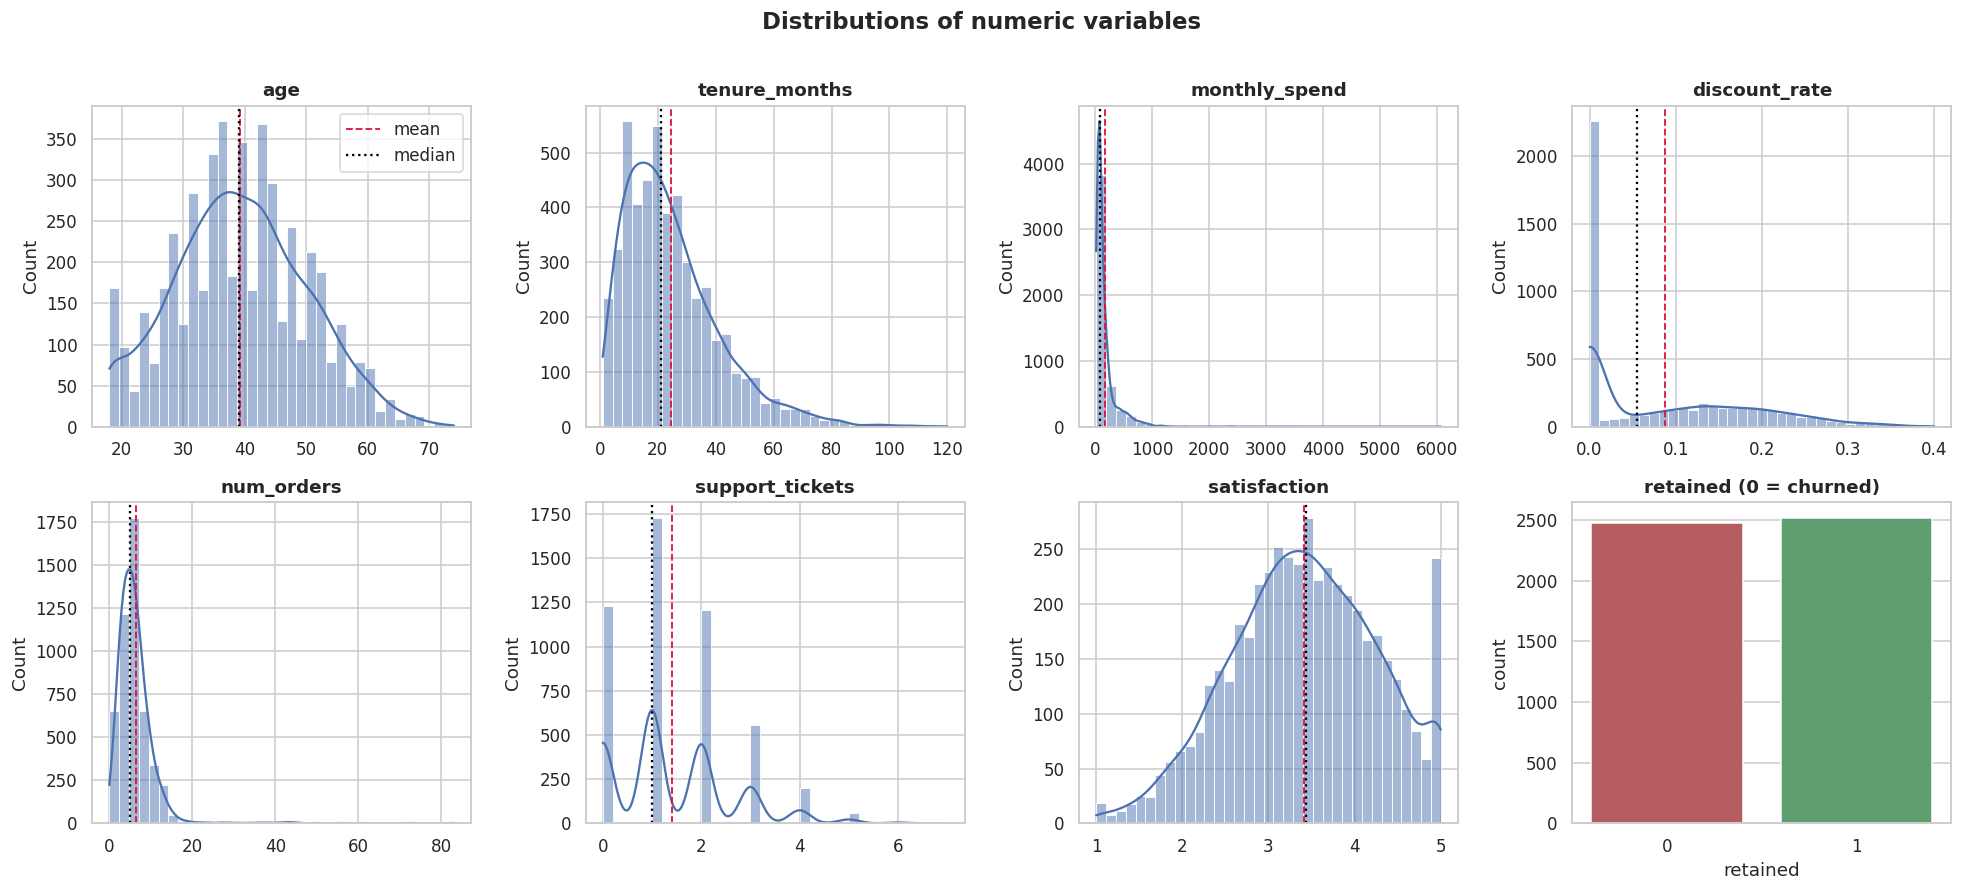

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c].dropna(), kde=True, bins=35, ax=ax, color="#4C72B0")
    ax.axvline(df[c].mean(), color="crimson", ls="--", lw=1.2, label="mean")
    ax.axvline(df[c].median(), color="black", ls=":", lw=1.5, label="median")
    ax.set_title(c); ax.set_xlabel("")
axes[0].legend()
sns.countplot(x="retained", data=df, ax=axes[7], palette=["#C44E52","#55A868"]); axes[7].set_title("retained (0 = churned)")
plt.suptitle("Distributions of numeric variables", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

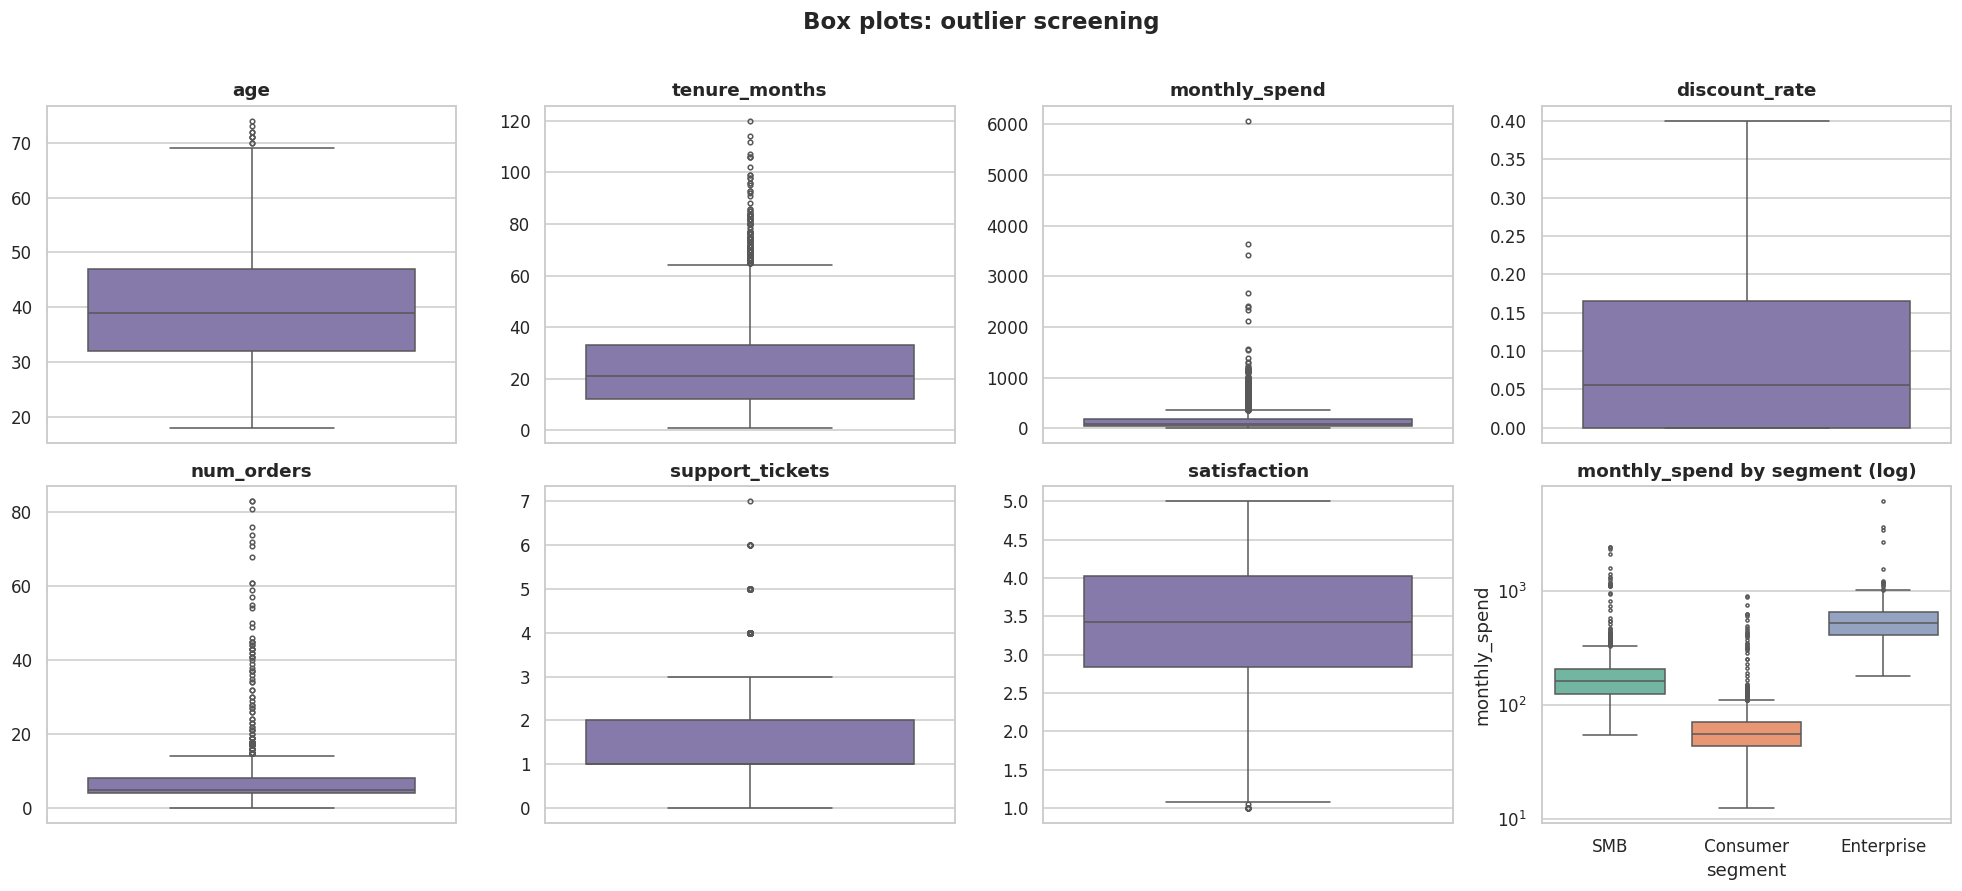

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#8172B2", fliersize=3); ax.set_title(c); ax.set_ylabel("")
sns.boxplot(x="segment", y="monthly_spend", data=df, ax=axes[7], palette="Set2", fliersize=2)
axes[7].set_yscale("log"); axes[7].set_title("monthly_spend by segment (log)")
plt.suptitle("Box plots: outlier screening", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25,.75]); i = q3-q1
    lo, hi = q1-1.5*i, q3+1.5*i
    return ((s<lo)|(s>hi)).sum(), lo, hi
rows = []
for c in num_cols:
    n_out, lo, hi = iqr_outliers(df[c].dropna())
    z = np.abs(stats.zscore(df[c].dropna()))
    rows.append((c, n_out, n_out/df[c].notna().sum()*100, lo, hi, (z>3).sum()))
outl = pd.DataFrame(rows, columns=["variable","IQR_outliers","outlier_%","lower_fence","upper_fence","|z|>3"]).set_index("variable")
display(outl)

# Within-segment check: are spend "outliers" really anomalies, or just Enterprise customers?
df["spend_z_in_segment"] = df.groupby("segment")["monthly_spend"].transform(lambda s: (s-s.mean())/s.std())
anom = df[df.spend_z_in_segment > 3].sort_values("monthly_spend", ascending=False)
print(f"Spend anomalies after adjusting for segment (z>3 within segment): {len(anom)}")
anom[["customer_id","segment","monthly_spend","num_orders","retained","spend_z_in_segment"]].head(8)

,IQR_outliers,outlier_%,lower_fence,upper_fence,|z|>3
variable,,,,,
age,9,0.182,9.500,69.500,4
tenure_months,155,3.100,-19.500,64.500,66
monthly_spend,547,10.940,-132.489,362.421,78
discount_rate,0,0.000,-0.247,0.412,7
num_orders,133,2.660,-2.000,14.000,56
support_tickets,274,5.480,-0.500,3.500,74
satisfaction,16,0.332,1.055,5.815,0


Spend anomalies after adjusting for segment (z>3 within segment): 55


,customer_id,segment,monthly_spend,num_orders,retained,spend_z_in_segment
4656,4657,Enterprise,"6,067.850",68,0,15.335
4661,4662,Enterprise,"3,629.720",43,1,8.538
2591,2592,Enterprise,"3,412.300",37,0,7.932
1113,1114,Enterprise,"2,673.040",26,0,5.870
54,55,SMB,"2,408.890",83,0,13.980
2699,2700,SMB,"2,400.620",71,0,13.928
105,106,SMB,"2,331.200",74,0,13.492
3323,3324,SMB,"2,112.620",72,0,12.116


**Why the within-segment check matters:** a pooled box plot flags Enterprise customers as "outliers" simply because their spend is structurally higher. Re-scoring spend *within* each segment isolates genuinely abnormal accounts — those worth auditing for billing errors, fraud, or white-glove treatment — rather than discarding legitimate high-value customers.

## 4. Correlation analysis

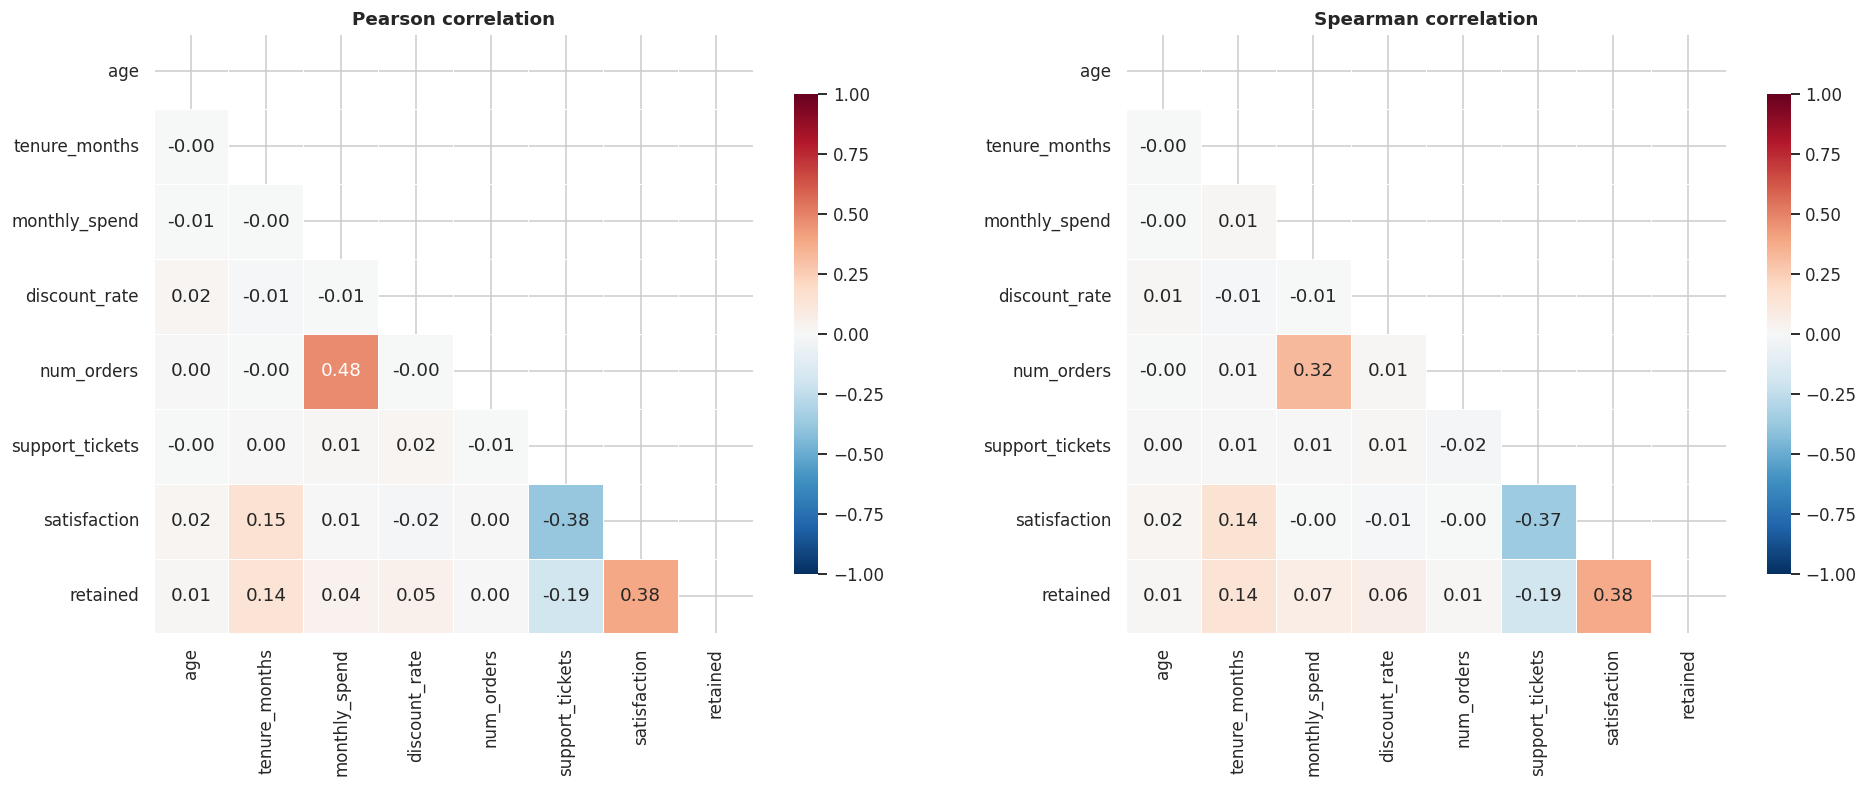

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
cols = num_cols + ["retained"]
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[cols].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                linewidths=.5, square=True, cbar_kws={"shrink": .8}, ax=ax)
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout(); plt.show()

In [10]:
corr_ret = (df[cols].corr(method="spearman")["retained"].drop("retained")
            .sort_values(key=abs, ascending=False).to_frame("spearman_r_with_retention"))
corr_ret["p_value"] = [stats.spearmanr(df[c], df["retained"], nan_policy="omit")[1] for c in corr_ret.index]
corr_ret

,spearman_r_with_retention,p_value
satisfaction,0.382,0.000
support_tickets,-0.188,0.000
tenure_months,0.136,0.000
monthly_spend,0.074,0.000
discount_rate,0.064,0.000
num_orders,0.013,0.343
age,0.008,0.550


**Pearson vs. Spearman:** Where the two diverge, the relationship is non-linear or driven by outliers (e.g. `monthly_spend`). Spearman is the safer guide for skewed variables. Note also that `discount_rate` shows only a weak linear correlation with retention — a hint that its effect may be non-monotonic, which Section 5 and Hypothesis 1 examine directly.

## 5. Multivariate patterns

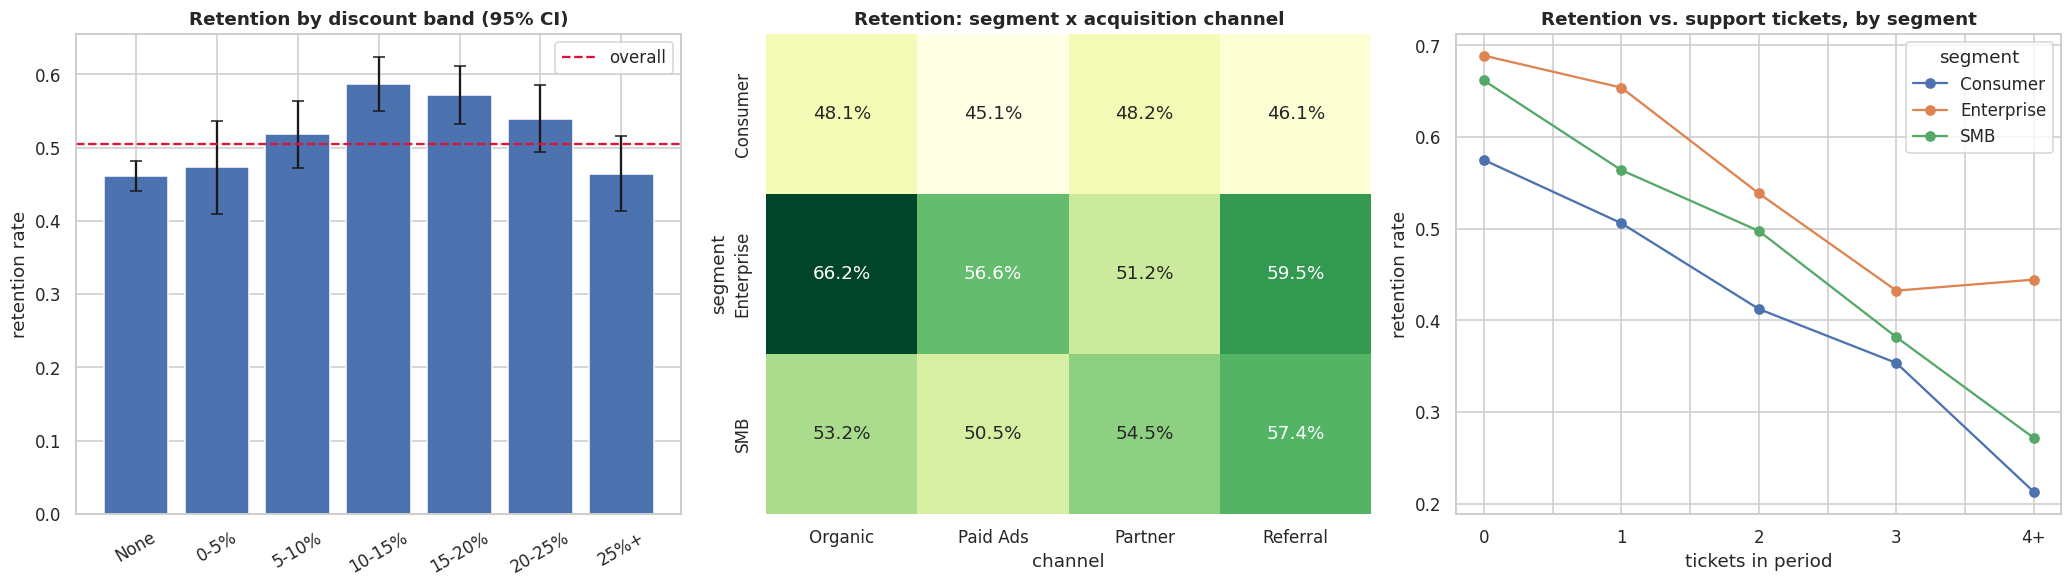

,customers,retention,se
discount_band,,,
None,2225,0.462,0.011
0-5%,239,0.473,0.032
5-10%,448,0.518,0.024
10-15%,668,0.587,0.019
15-20%,598,0.572,0.020
20-25%,458,0.539,0.023
25%+,364,0.464,0.026


In [11]:
df["discount_band"] = pd.cut(df.discount_rate, [-.001, 0, .05, .10, .15, .20, .25, .41],
                             labels=["None","0-5%","5-10%","10-15%","15-20%","20-25%","25%+"])
band = df.groupby("discount_band", observed=True).agg(customers=("retained","size"), retention=("retained","mean"))
band["se"] = np.sqrt(band.retention*(1-band.retention)/band.customers)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].bar(band.index.astype(str), band.retention, yerr=1.96*band.se, capsize=4, color="#4C72B0")
axes[0].axhline(df.retained.mean(), color="crimson", ls="--", label="overall"); axes[0].legend()
axes[0].set_title("Retention by discount band (95% CI)"); axes[0].set_ylabel("retention rate"); axes[0].tick_params(axis="x", rotation=30)

piv = df.pivot_table(index="segment", columns="channel", values="retained", aggfunc="mean")
sns.heatmap(piv, annot=True, fmt=".1%", cmap="YlGn", ax=axes[1], cbar=False)
axes[1].set_title("Retention: segment x acquisition channel")

df["ticket_band"] = pd.cut(df.support_tickets, [-1,0,1,2,3,100], labels=["0","1","2","3","4+"])
piv2 = df.pivot_table(index="ticket_band", columns="segment", values="retained", aggfunc="mean", observed=True)
piv2.plot(marker="o", ax=axes[2]); axes[2].set_title("Retention vs. support tickets, by segment")
axes[2].set_ylabel("retention rate"); axes[2].set_xlabel("tickets in period")
plt.tight_layout(); plt.show()
band

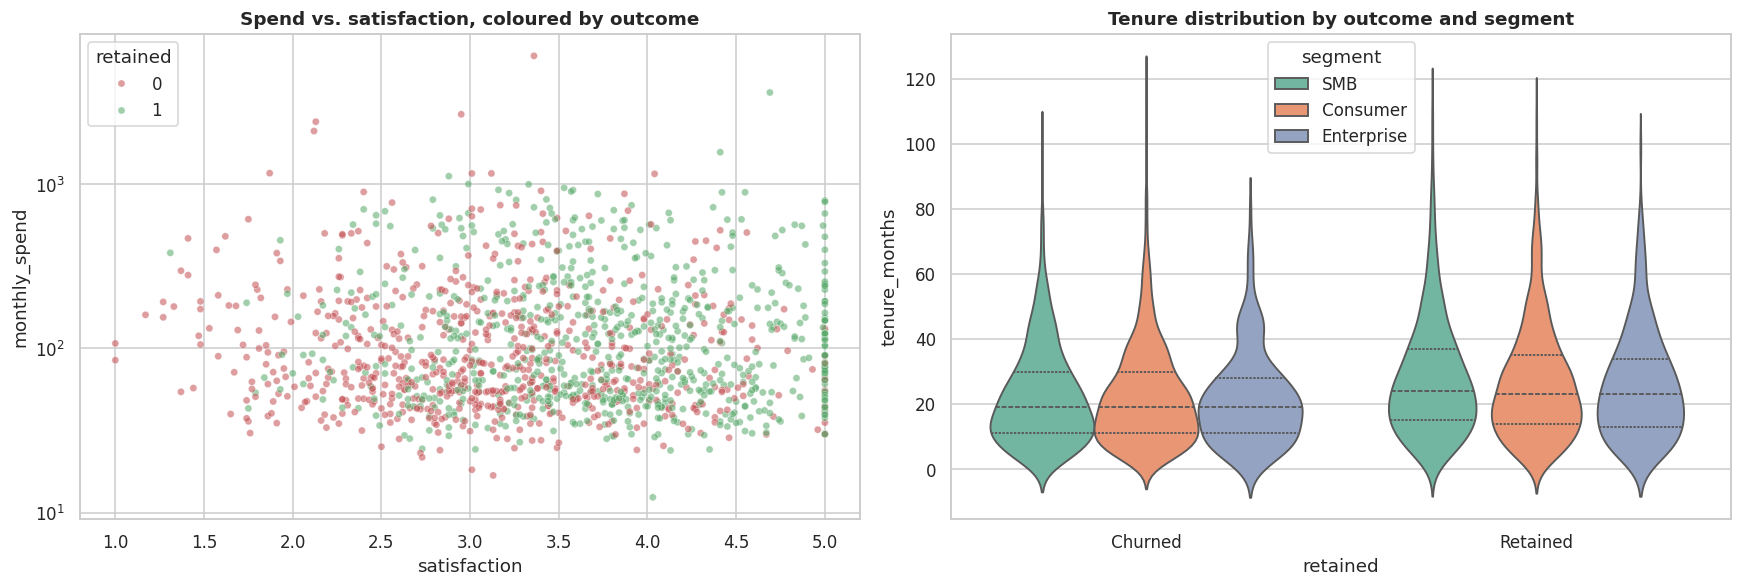

In [12]:
samp = df.sample(1500, random_state=1).dropna(subset=["satisfaction"])
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=samp, x="satisfaction", y="monthly_spend", hue="retained", palette=["#C44E52","#55A868"],
                alpha=.55, s=22, ax=axes[0]); axes[0].set_yscale("log"); axes[0].set_title("Spend vs. satisfaction, coloured by outcome")
sns.violinplot(data=df, x="retained", y="tenure_months", hue="segment", split=False, inner="quartile", ax=axes[1], palette="Set2")
axes[1].set_title("Tenure distribution by outcome and segment"); axes[1].set_xticklabels(["Churned","Retained"])
plt.tight_layout(); plt.show()

## 6. Hypothesis testing
All tests use α = 0.05. Non-parametric tests are used where distributions are visibly non-normal.

| # | Business hypothesis | H0 | Test |
|---|---|---|---|
| H1 | Discounted customers are retained at a higher rate than non-discounted ones, with diminishing returns at deep discounts | No difference in retention | χ² test, then a quadratic logistic fit |
| H2 | Satisfaction is higher among retained than churned customers | Same distribution | Mann-Whitney U |
| H3 | Heavy support users (3+ tickets) churn more than light users | Same retention rate | χ² test + Cramér's V |

### H1a: any discount vs none

retained      Churned  Retained
has_discount                   
No discount      1198      1027
Discount         1280      1495
Retention: discount 53.9% vs none 46.2% | chi2=29.11, p=6.849e-08


### H1b: quadratic dose-response (discounted customers)

                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.3467      0.141     -2.456      0.014      -0.623      -0.070
discount_rate             8.6397      1.776      4.866      0.000       5.160      12.120
I(discount_rate ** 2)   -27.6897      5.077     -5.454      0.000     -37.641     -17.738

Quadratic term p = 4.933e-08; estimated retention-maximising discount ≈ 15.6%


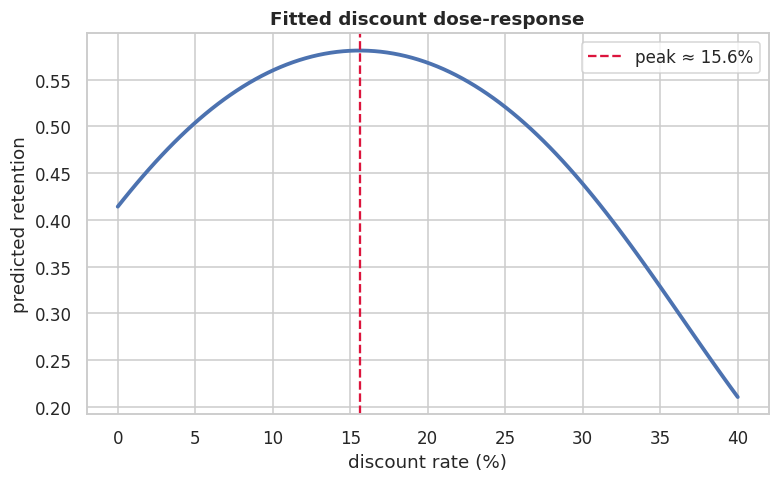

In [13]:
# ---------- H1: discount vs retention ----------
df["has_discount"] = (df.discount_rate > 0).astype(int)
ct = pd.crosstab(df.has_discount, df.retained)
chi2, p1, dof, _ = stats.chi2_contingency(ct)
r_disc, r_none = df.loc[df.has_discount==1,"retained"].mean(), df.loc[df.has_discount==0,"retained"].mean()
display(Markdown("### H1a: any discount vs none"))
print(ct.rename(index={0:"No discount",1:"Discount"}, columns={0:"Churned",1:"Retained"}))
print(f"Retention: discount {r_disc:.1%} vs none {r_none:.1%} | chi2={chi2:.2f}, p={p1:.4g}")

# H1b: is the dose-response inverted-U?  (discounted customers only)
d = df[df.has_discount==1].copy()
m_quad = smf.logit("retained ~ discount_rate + I(discount_rate**2)", data=d).fit(disp=0)
b1, b2 = m_quad.params["discount_rate"], m_quad.params["I(discount_rate ** 2)"]
peak = -b1/(2*b2) if b2 < 0 else np.nan
display(Markdown("### H1b: quadratic dose-response (discounted customers)"))
print(m_quad.summary().tables[1])
print(f"\nQuadratic term p = {m_quad.pvalues['I(discount_rate ** 2)']:.4g}; estimated retention-maximising discount ≈ {peak:.1%}")

x = np.linspace(0, .4, 100); fit = m_quad.predict(pd.DataFrame({"discount_rate": x}))
plt.figure(figsize=(8,4.5)); plt.plot(x*100, fit, lw=2.5, color="#4C72B0")
plt.axvline(peak*100, color="crimson", ls="--", label=f"peak ≈ {peak:.1%}"); plt.legend()
plt.xlabel("discount rate (%)"); plt.ylabel("predicted retention"); plt.title("Fitted discount dose-response"); plt.show()

Median satisfaction: retained 3.76 vs churned 3.08
Mann-Whitney U=4,179,983, p=2.36e-155 | rank-biserial r=0.441 | Cohen's d=0.83


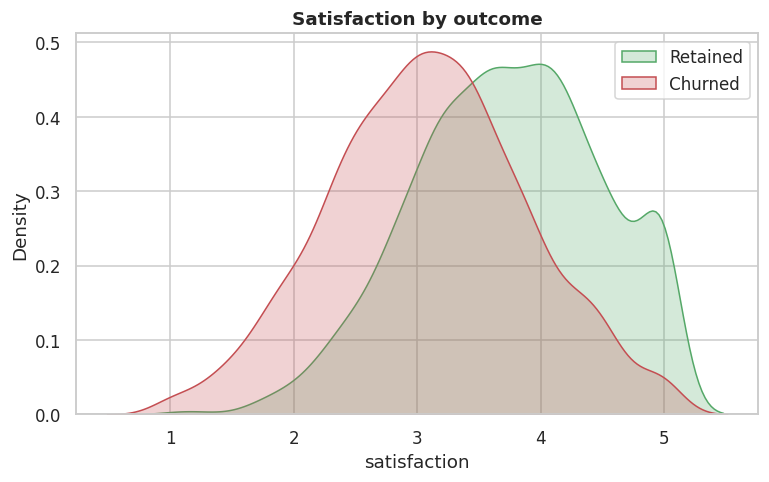

In [14]:
# ---------- H2: satisfaction vs retention ----------
a = df.loc[df.retained==1,"satisfaction"].dropna(); b = df.loc[df.retained==0,"satisfaction"].dropna()
u, p2 = stats.mannwhitneyu(a, b, alternative="greater")
rbc = 2*u/(len(a)*len(b)) - 1      # rank-biserial effect size
cohen = (a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2)
print(f"Median satisfaction: retained {a.median():.2f} vs churned {b.median():.2f}")
print(f"Mann-Whitney U={u:,.0f}, p={p2:.3g} | rank-biserial r={rbc:.3f} | Cohen's d={cohen:.2f}")
plt.figure(figsize=(8,4.5)); sns.kdeplot(a, fill=True, label="Retained", color="#55A868"); sns.kdeplot(b, fill=True, label="Churned", color="#C44E52")
plt.title("Satisfaction by outcome"); plt.legend(); plt.show()

In [15]:
# ---------- H3: heavy support users churn more ----------
df["heavy_support"] = (df.support_tickets >= 3).astype(int)
ct3 = pd.crosstab(df.heavy_support, df.retained)
chi3, p3, _, _ = stats.chi2_contingency(ct3)
cramers_v = np.sqrt(chi3/ct3.values.sum())
rh, rl = df.loc[df.heavy_support==1,"retained"].mean(), df.loc[df.heavy_support==0,"retained"].mean()
# bootstrap CI for the retention gap
rng = np.random.default_rng(0); h = df.loc[df.heavy_support==1,"retained"].values; l = df.loc[df.heavy_support==0,"retained"].values
boot = [rng.choice(h, len(h)).mean() - rng.choice(l, len(l)).mean() for _ in range(3000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Share of customers with 3+ tickets: {df.heavy_support.mean():.1%}")
print(f"Retention: heavy {rh:.1%} vs light {rl:.1%} | gap {rh-rl:+.1%} (95% bootstrap CI {lo:+.1%} to {hi:+.1%})")
print(f"chi2={chi3:.2f}, p={p3:.3g}, Cramer's V={cramers_v:.3f}")

Share of customers with 3+ tickets: 16.6%
Retention: heavy 33.5% vs light 53.8% | gap -20.4% (95% bootstrap CI -23.9% to -16.9%)
chi2=114.22, p=1.17e-26, Cramer's V=0.151


In [16]:
summary = pd.DataFrame([
    ["H1a", "Any discount lifts retention", f"{r_disc:.1%} vs {r_none:.1%}", p1, "Reject H0" if p1<.05 else "Fail to reject"],
    ["H1b", "Discount effect is non-linear (inverted-U)", f"peak ≈ {peak:.1%}", m_quad.pvalues['I(discount_rate ** 2)'], "Reject H0" if m_quad.pvalues['I(discount_rate ** 2)']<.05 else "Fail to reject"],
    ["H2",  "Satisfaction higher among retained", f"d = {cohen:.2f}", p2, "Reject H0" if p2<.05 else "Fail to reject"],
    ["H3",  "Heavy support users churn more", f"gap {rh-rl:+.1%}", p3, "Reject H0" if p3<.05 else "Fail to reject"],
], columns=["id","hypothesis","effect","p_value","decision"]).set_index("id")
summary

,hypothesis,effect,p_value,decision
id,,,,
H1a,Any discount lifts retention,53.9% vs 46.2%,0.000,Reject H0
H1b,Discount effect is non-linear (inverted-U),peak ≈ 15.6%,0.000,Reject H0
H2,Satisfaction higher among retained,d = 0.83,0.000,Reject H0
H3,Heavy support users churn more,gap -20.4%,0.000,Reject H0


## 7. Multivariate model — do the effects survive controls?

,odds_ratio,ci_low,ci_high,p_value
satisfaction,2.672,2.445,2.921,0.000
discount_rate,"2,969.760",438.436,"20,115.786",0.000
I(discount_rate ** 2),0.000,0.000,0.000,0.000
tenure_months,1.013,1.009,1.017,0.000
support_tickets,0.890,0.840,0.943,0.000
C(segment)[T.Enterprise],2.174,1.466,3.224,0.000
C(segment)[T.SMB],1.439,1.161,1.783,0.001
C(channel)[T.Paid Ads],0.828,0.708,0.968,0.018
C(channel)[T.Partner],0.905,0.746,1.099,0.314
C(channel)[T.Referral],0.914,0.766,1.090,0.316


n = 4,772 | pseudo-R² = 0.140


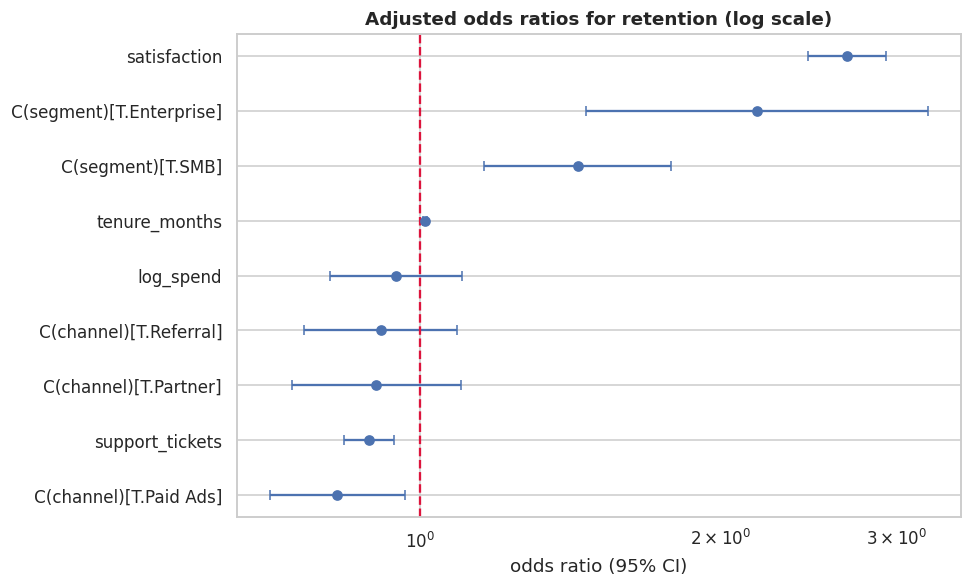

In [17]:
model_df = df.dropna(subset=["satisfaction","age"]).copy()
model_df["log_spend"] = np.log(model_df.monthly_spend)
m = smf.logit("retained ~ discount_rate + I(discount_rate**2) + satisfaction + support_tickets + tenure_months + log_spend + C(segment) + C(channel)",
              data=model_df).fit(disp=0)
res = pd.DataFrame({"odds_ratio": np.exp(m.params), "ci_low": np.exp(m.conf_int()[0]),
                    "ci_high": np.exp(m.conf_int()[1]), "p_value": m.pvalues}).drop("Intercept")
display(res.sort_values("p_value"))
print(f"n = {int(m.nobs):,} | pseudo-R² = {m.prsquared:.3f}")

plot = res.drop(index=[i for i in res.index if "discount_rate" in i]).sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(plot.odds_ratio, range(len(plot)), xerr=[plot.odds_ratio-plot.ci_low, plot.ci_high-plot.odds_ratio], fmt="o", color="#4C72B0", capsize=3)
ax.axvline(1, color="crimson", ls="--"); ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot.index); ax.set_xscale("log")
ax.set_title("Adjusted odds ratios for retention (log scale)"); ax.set_xlabel("odds ratio (95% CI)"); plt.tight_layout(); plt.show()

## 8. Top 5 critical findings

In [18]:
sat_or  = res.loc["satisfaction","odds_ratio"]; tix_or = res.loc["support_tickets","odds_ratio"]
best    = band.retention.idxmax(); best_r = band.retention.max(); worst_d = band.loc[band.index[-1],"retention"]
cv_top  = desc["CV"].idxmax()
seg_ret = df.groupby("segment").retained.mean().sort_values()
spend_med = df.monthly_spend.median(); spend_mean = df.monthly_spend.mean()
n_anom = len(anom)

display(Markdown(f'''
### 1. Discounts help, but only up to a point (H1)
Discounted customers are retained at **{r_disc:.1%}** versus **{r_none:.1%}** for non-discounted customers (χ² p = {p1:.2g}). The dose-response is an **inverted U**: the fitted retention peak is near a **{peak:.0%}** discount, and the best observed band (**{best}**) retains **{best_r:.1%}**. The deepest band (25%+) falls back to **{worst_d:.1%}**. *Action:* cap standard discounts near the peak; deeper discounts cost margin and buy no extra retention.

### 2. Satisfaction is the strongest controllable lever (H2)
Retained customers have materially higher satisfaction (median **{a.median():.2f}** vs **{b.median():.2f}**, Cohen's d = **{cohen:.2f}**, p = {p2:.2g}). After adjusting for everything else, each +1 point of satisfaction multiplies the odds of retention by **{sat_or:.2f}x**. *Action:* treat satisfaction score as a leading churn indicator and trigger outreach below a threshold.

### 3. Support friction predicts churn (H3)
Customers with 3+ tickets (**{df.heavy_support.mean():.0%}** of the base) are retained at **{rh:.1%}** versus **{rl:.1%}** (gap **{rh-rl:+.1%}**, 95% CI {lo:+.1%} to {hi:+.1%}). Each extra ticket carries an adjusted odds ratio of **{tix_or:.2f}**, and part of the effect operates *through* lower satisfaction. *Action:* escalate accounts at ticket #2 and fix the root causes of repeat contacts.

### 4. Spend is heavily skewed; pooled outlier rules mislead
`monthly_spend` has mean **{spend_mean:,.0f}** against a median of **{spend_med:,.0f}** (skew = {desc.loc["monthly_spend","skew"]:.1f}), and `{cv_top}` has the highest coefficient of variation. Pooled IQR rules flag **{outl.loc["monthly_spend","IQR_outliers"]:,.0f}** spend "outliers", most of them ordinary Enterprise accounts. Scoring *within segment* isolates **{n_anom}** genuinely abnormal accounts. *Action:* use medians and log-scale for reporting, and audit the within-segment anomalies rather than dropping all high spenders.

### 5. Retention differs by segment, and linear correlations understate the story
Retention ranges from **{seg_ret.iloc[0]:.1%}** ({seg_ret.index[0]}) to **{seg_ret.iloc[-1]:.1%}** ({seg_ret.index[-1]}). The raw Pearson correlation of `discount_rate` with retention is only **{df[["discount_rate","retained"]].corr().iloc[0,1]:.2f}** because the relationship is non-monotonic, so a correlation matrix alone would have wrongly suggested discounts are irrelevant. *Action:* segment-specific retention playbooks, and model non-linear effects before drawing conclusions.
'''))


### 1. Discounts help, but only up to a point (H1)
Discounted customers are retained at **53.9%** versus **46.2%** for non-discounted customers (χ² p = 6.8e-08). The dose-response is an **inverted U**: the fitted retention peak is near a **16%** discount, and the best observed band (**10-15%**) retains **58.7%**. The deepest band (25%+) falls back to **46.4%**. *Action:* cap standard discounts near the peak; deeper discounts cost margin and buy no extra retention.

### 2. Satisfaction is the strongest controllable lever (H2)
Retained customers have materially higher satisfaction (median **3.76** vs **3.08**, Cohen's d = **0.83**, p = 2.4e-155). After adjusting for everything else, each +1 point of satisfaction multiplies the odds of retention by **2.67x**. *Action:* treat satisfaction score as a leading churn indicator and trigger outreach below a threshold.

### 3. Support friction predicts churn (H3)
Customers with 3+ tickets (**17%** of the base) are retained at **33.5%** versus **53.8%** (gap **-20.4%**, 95% CI -23.9% to -16.9%). Each extra ticket carries an adjusted odds ratio of **0.89**, and part of the effect operates *through* lower satisfaction. *Action:* escalate accounts at ticket #2 and fix the root causes of repeat contacts.

### 4. Spend is heavily skewed; pooled outlier rules mislead
`monthly_spend` has mean **161** against a median of **83** (skew = 7.6), and `monthly_spend` has the highest coefficient of variation. Pooled IQR rules flag **547** spend "outliers", most of them ordinary Enterprise accounts. Scoring *within segment* isolates **55** genuinely abnormal accounts. *Action:* use medians and log-scale for reporting, and audit the within-segment anomalies rather than dropping all high spenders.

### 5. Retention differs by segment, and linear correlations understate the story
Retention ranges from **46.8%** (Consumer) to **59.6%** (Enterprise). The raw Pearson correlation of `discount_rate` with retention is only **0.05** because the relationship is non-monotonic, so a correlation matrix alone would have wrongly suggested discounts are irrelevant. *Action:* segment-specific retention playbooks, and model non-linear effects before drawing conclusions.


### Caveats & next steps
- **Correlation ≠ causation.** Discounts were not randomly assigned; any real causal claim needs an A/B test or uplift model.
- **Synthetic data:** the numbers above illustrate the method. Re-run the notebook on production data (`USE_REAL_DATA = True`) to obtain real findings; all commentary in Section 8 updates automatically.
- **Multiple testing:** four tests at α = 0.05 carry a modest false-positive risk; apply a Bonferroni/Holm correction if extending this list.
- **Next steps:** gradient-boosted churn model with SHAP, survival analysis on tenure, and a discount-depth A/B experiment around the estimated optimum.